> **学生作业版说明**  
> 本 Notebook 为学生作业版，部分关键代码单元已被替换为待补全骨架。  
> 请结合 `README.md`、`assignment.md` 与 `starter.py` 完成实验。  
> 提交前请确认：代码可运行、指标齐全、报告完整。

In [1]:
import os, urllib.request
for f in ['bike.csv', 'voice.csv']:
    if not os.path.exists(f):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Heptazero/ml-course-labs/main/machine-learning/homework/' + f, f)

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor as SkDecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier as SkDecisionTreeClassifier

### 任务1：决策树CART算法基类
#### 【任务目标】
&ensp;&ensp;实现决策树CART算法基类
#### 【任务步骤】
1. 定义决策树节点数据结构
2. 实现决策树CART算法基类

In [3]:
# 定义决策树节点数据结构
class Node:
    j = None
    theta = None
    p = None
    left = None
    right = None

"""
类说明：DecisionTreeBase
    编写代码实现决策树CART算法的基类
    
Parameters:
        max_depth         - 决策树深度
    feature_sample_rate   - 选取特征的比例
        get_score         - 分值函数指针
Returns:
"""
class DecisionTreeBase:
    def __init__(self, max_depth, feature_sample_rate, get_score):
        self.max_depth = max_depth
        self.feature_sample_rate = feature_sample_rate
        self.get_score = get_score
  
    # 将数据按照特征j的取值是否大于阈值theta分成两部分
    def split_data(self, j, theta, X, idx):
#####  Start Code Here  #####  
        idx = np.asarray(idx)
        mask = X[idx, j] <= theta
        return idx[mask], idx[~mask]
    
    # 按照比例选取特征组
    def get_random_features(self, n):
        k = max(1, int(n * self.feature_sample_rate))
        return np.random.choice(n, k, replace=False)
    
    # 采用贪心策略来寻找最优数据划分
    def find_best_split(self, X, y, idx):
        # 获取X的维度
        _, n = X.shape
        
        # 初始化参数
        best_score = float("inf")
        best_j = None
        best_theta = None
        best_idx1 = None
        best_idx2 = None
        
        # 调用get_random_features函数随机选取一组特征
        selected_j = self.get_random_features(n)
        
        # 遍历选择的特征
        for j in selected_j:
            
            # 计算特征j的不同取值，作为备选的阈值theta
            thetas = np.unique(X[idx, j])
            
            # 遍历所有的theta
            for theta in thetas:
                
                # 将数据按照特征j的取值是否大于阈值theta分成两部分 
                idx1, idx2 = self.split_data(j, theta, X, idx)
                
                # 确保划分的两部分都不是空集
                if len(idx1) == 0 or len(idx2) == 0:
                    continue
                
                # 对每一部分数据计算其分值
                score1 = self.get_score(y, idx1)
                score2 = self.get_score(y, idx2)
                
                # 计算两部分分值的加权和
                score = (len(idx1) * score1 + len(idx2) * score2) / len(idx)
                
                # 更新参数
                if score < best_score:
                    best_score = score
                    best_j = j
                    best_theta = theta
                    best_idx1 = idx1
                    best_idx2 = idx2
                    
        return best_j, best_theta, best_idx1, best_idx2, best_score
    
    # 生成一颗深度不超过max_depth的树
    def generate_tree(self, X, y, idx, d):
        # 生成根节点
        r = Node()
        r.p = np.average(y[idx], axis=0)
        
        # 判断深度是否等于0或者是否只有1条训练数据
        if d == 0 or len(idx) <= 1:
            return r
        
        # 计算不做数据划分时得到的目标函数值
        no_split_score = self.get_score(y, idx)
        
        # 寻找最优数据划分
        j, theta, idx1, idx2, best_score = self.find_best_split(X, y, idx)
        
        # 判断划分数据是否带来益处，如果有则记录这一划分信息
        if j is None or best_score >= no_split_score:
            return r
        r.j = j
        r.theta = theta
        
#####  End Code Here  #####    
        # 递归生成当前节点的左节点与右节点
        r.left = self.generate_tree(X, y, idx1, d - 1)
        r.right = self.generate_tree(X, y, idx2, d - 1)
        return r
    
    # CART算法入口
    def fit(self, X, y):
        self.root = self.generate_tree(X, y, np.arange(len(X)), self.max_depth)
    
    def get_prediction(self, r, x):
        if r.left == None and r.right == None:
            return r.p
        value = x[r.j]
        if value <= r.theta:
            return self.get_prediction(r.left, x)
        else:
            return self.get_prediction(r.right, x)

    def predict(self, X):
        y = list()
        for i in range(len(X)):
            y.append(self.get_prediction(self.root, X[i]))
        return np.array(y)

### 任务2：决策树回归问题和分类问题的CART算法
#### 【任务目标】
&ensp;&ensp;实现决策树回归问题和分类问题的CART算法
#### 【任务步骤】
1. 实现方差的计算
2. 实现熵的定义
3. 实现决策树回归问题和分类问题的CART算法

In [4]:
# 计算方差
def get_var(y, idx):
    y_avg = np.average(y[idx]) * np.ones(len(idx))
    return np.linalg.norm(y_avg - y[idx], 2) ** 2 / len(idx)

# 继承决策树基类
class DecisionTreeRegressor(DecisionTreeBase):
    def __init__(self, max_depth, feature_sample_rate=1.0):
        super().__init__(max_depth, feature_sample_rate, get_var)
    
# 熵的定义
def get_entropy(y, idx):
    _, k = y.shape
    p = np.average(y[idx], axis = 0)
    return - np.log(p + 0.001 * np.random.rand(k)).dot(p.T)

# 继承决策树基类
class DecisionTreeClassifier(DecisionTreeBase):
    def __init__(self, max_depth, feature_sample_rate=1.0):
        super().__init__(max_depth, feature_sample_rate, get_entropy)
        
    # 完成概率预测任务
    def predict_proba(self, X):
        return super().predict(X)
    
    # 将概率预测结果转为类别预测
    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

### 任务3：共享单车问题
#### 【数据集介绍】
&ensp;&ensp;共享单车系统为人们的出行提供了极大的便利。人们可以从一个地点租车，并于另一
地点还车。一个共享单车系统每天都会产生大量的租车数据。数据中包括出行时间、出发
地、目的地等信息。共享单车问题的任务是根据租车数据预测每个共享单车服务点的单车
需求量，从而提前准备需储备的单车数量。
在这个问题中，每一条数据有8个特征：钟点(hour)、季节(season)、是否为节假日
(holiday)、是否为周末(wkday)、天气状况(weather)、气温(temp)、湿度(hum)和风速
(wdspd)。数据的标签是单车的需求量(count)。
#### 【任务目标】
&ensp;&ensp;训练一颗深度不超过2的决策树，并用来预测单车需求量。
#### 【任务步骤】
1. 加载共享单车数据集
2. 按照一定比例划分训练集和测试集
3. 定义模型进行训练
4. 计算 r2 系数并输出

In [5]:
# 获取数据
def get_data():
    df = pd.read_csv("./bike.csv")
    df.datetime = df.datetime.apply(pd.to_datetime)
    df['hour'] = df.datetime.apply(lambda x: x.hour)
    y = df['count'].values
    df = df.drop(['datetime', 'casual', 'registered', 'count'], axis=1)
    X = df.values
    return X, y

# 获取共享单车数据集
X_bike, y_bike = get_data()

# 划分训练集和测试集 训练集：测试集 = 1:1
X_train, X_test, y_train, y_test = train_test_split(X_bike, y_bike, test_size=0.5, random_state=42)

# 定义决策树回归模型
reg = DecisionTreeRegressor(max_depth=2, feature_sample_rate=1.0)

# 训练模型
reg.fit(X_train, y_train)

# 预测
y_pred = reg.predict(X_test)

print("tree r2 = {}".format(r2_score(y_test, y_pred)))
print("tree mse = {}".format(mean_squared_error(y_test, y_pred)))

# sklearn 对照验证
sk_reg = SkDecisionTreeRegressor(max_depth=2, random_state=42)
sk_reg.fit(X_train, y_train)
print("sklearn r2 = {}".format(r2_score(y_test, sk_reg.predict(X_test))))

tree r2 = 0.3949458459256605
tree mse = 19630.447053586347
sklearn r2 = 0.3949458459256605


max_depth =  1 | train R2 = 0.3198 | test R2 = 0.3033
max_depth =  2 | train R2 = 0.4071 | test R2 = 0.3949
max_depth =  4 | train R2 = 0.5569 | test R2 = 0.5429


max_depth =  6 | train R2 = 0.6827 | test R2 = 0.6624


max_depth =  8 | train R2 = 0.7958 | test R2 = 0.7552


max_depth = 10 | train R2 = 0.8749 | test R2 = 0.7808


max_depth = 12 | train R2 = 0.9244 | test R2 = 0.7716


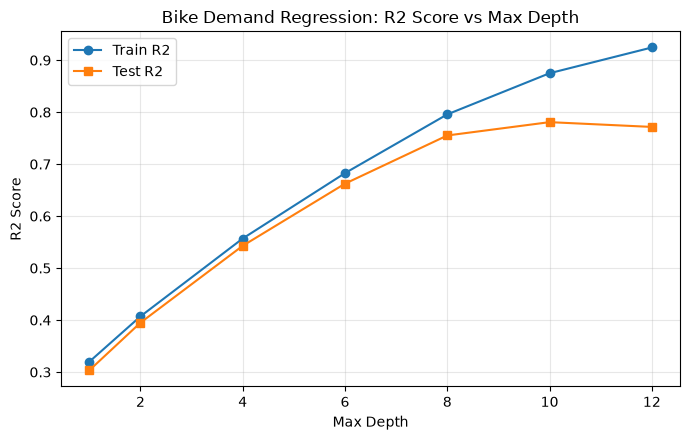

In [6]:
# 共享单车回归任务：不同树深度对比
bike_depths = [1, 2, 4, 6, 8, 10, 12]
bike_train_r2 = []
bike_test_r2 = []
for d in bike_depths:
    m = DecisionTreeRegressor(max_depth=d, feature_sample_rate=1.0)
    m.fit(X_train, y_train)
    tr_r2 = r2_score(y_train, m.predict(X_train))
    te_r2 = r2_score(y_test, m.predict(X_test))
    bike_train_r2.append(tr_r2)
    bike_test_r2.append(te_r2)
    print(f"max_depth = {d:2d} | train R2 = {tr_r2:.4f} | test R2 = {te_r2:.4f}")

plt.figure(figsize=(7, 4.5))
plt.plot(bike_depths, bike_train_r2, marker='o', label='Train R2')
plt.plot(bike_depths, bike_test_r2, marker='s', label='Test R2')
plt.xlabel('Max Depth')
plt.ylabel('R2 Score')
plt.title('Bike Demand Regression: R2 Score vs Max Depth')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 任务4：语音识别问题
#### 【数据集介绍】
&ensp;&ensp;语音识别是机器学习的重要应用场景。本例考察一个简单的语音识别问题：根据一段
语音的特征，判断发声者的性别。在这个问题中，每条训练数据含有21个刻画声音特点的
变量，例如音域(IQR)、音频(meanfun)、熵谱(sp.ent)等。数据还含有一个性别标签，表示
声音来自男性还是女性。
#### 【任务目标】
&ensp;&ensp;训练一颗深度为5的决策树来推断发声者的性别
#### 【任务步骤】
1. 加载数据集
2. 按照一定比例划分训练集和测试集
3. 将标签转为向量形式
4. 定义模型进行训练 
5. 计算准确率并输出

In [7]:
# 获取数据
def get_data():
    df = pd.read_csv("./voice.csv")
    y = (df["label"].values == "male").astype(int)
    df = df.drop(['label'], axis=1)
    X = df.values
    return X, y.reshape(-1, 1)

# 获取数据
X_voice, y_voice = get_data()

# 划分训练集和测试集 训练集：测试集 = 1:1
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(X_voice, y_voice, test_size=0.5, random_state=42)

# 定义决策树分类模型
np.random.seed(42)
clf = DecisionTreeClassifier(max_depth=5, feature_sample_rate=1.0)

# 运用OneHotEncoder将标签转化为向量形式
ohe = OneHotEncoder(sparse_output=False)
y_train_ohe = ohe.fit_transform(y_train_v)

# 训练模型
clf.fit(X_train_v, y_train_ohe)

# 预测
y_pred_v = clf.predict(X_test_v)

accuracy = accuracy_score(y_test_v, y_pred_v)
precision = precision_score(y_test_v, y_pred_v)
print("accuracy = {}".format(accuracy))
print("precision = {}".format(precision))

# sklearn 对照验证
sk_clf = SkDecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)
sk_clf.fit(X_train_v, y_train_v.ravel())
sk_pred_v = sk_clf.predict(X_test_v)
print("sklearn accuracy = {}".format(accuracy_score(y_test_v, sk_pred_v)))
print("sklearn precision = {}".format(precision_score(y_test_v, sk_pred_v)))

accuracy = 0.9659090909090909
precision = 0.9748110831234257
sklearn accuracy = 0.9659090909090909
sklearn precision = 0.9736180904522613


max_depth =  1 | train acc = 0.9615 | test acc = 0.9444


max_depth =  2 | train acc = 0.9615 | test acc = 0.9444


max_depth =  3 | train acc = 0.9716 | test acc = 0.9602


max_depth =  5 | train acc = 0.9905 | test acc = 0.9659


max_depth =  7 | train acc = 0.9956 | test acc = 0.9609


max_depth =  9 | train acc = 0.9956 | test acc = 0.9621


max_depth = 12 | train acc = 0.9994 | test acc = 0.9665


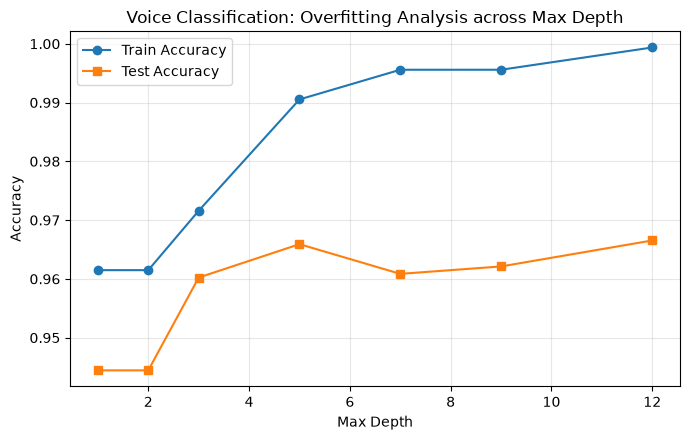

In [8]:
# 语音分类任务：不同树深度下的过拟合分析
voice_depths = [1, 2, 3, 5, 7, 9, 12]
voice_train_acc = []
voice_test_acc = []
for d in voice_depths:
    np.random.seed(42)
    m = DecisionTreeClassifier(max_depth=d, feature_sample_rate=1.0)
    m.fit(X_train_v, y_train_ohe)
    tr_acc = accuracy_score(y_train_v, m.predict(X_train_v))
    te_acc = accuracy_score(y_test_v, m.predict(X_test_v))
    voice_train_acc.append(tr_acc)
    voice_test_acc.append(te_acc)
    print(f"max_depth = {d:2d} | train acc = {tr_acc:.4f} | test acc = {te_acc:.4f}")

plt.figure(figsize=(7, 4.5))
plt.plot(voice_depths, voice_train_acc, marker='o', label='Train Accuracy')
plt.plot(voice_depths, voice_test_acc, marker='s', label='Test Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Voice Classification: Overfitting Analysis across Max Depth')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()